# Redes neuronales convolucionales

In [ ]:
import numpy as np
import matplotlib.pylab as plt
import sympy as sp
import scipy as sc
#import tensorflow as tf
#https://setosa.io/ev/image-kernels/

In [ ]:
import numpy as np
import pandas as pd
import itertools as it
# import datascience as ds
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits

plt.rcParams.update({
    "figure.figsize": (11, 4),
    "axes.grid": True,
    "font.size": 11
})

from pprint import pprint
import json
from tabulate import tabulate
from IPython.display import display, Image, display_svg # Display functions
from IPython.display import Markdown, Math, Latex # Text formatting
from IPython.display import Javascript, IFrame, HTML # Web elements

def dLatex(self):
  # Displays the input string as LaTeX.
  return display(Latex(self))
def dMarkdown(self):
  # Displays the input string as Markdown.
  return display(Markdown(self))

# Avoids scroll-in-the-scroll in the entire Notebook
# https://stackoverflow.com/a/66891328
def resize_colab_cell():
  display(Javascript(
      'google.colab.output.setIframeHeight'+
      '(0, true, {maxHeight: 4000})'
      ))
get_ipython().events.register(
    'pre_run_cell',resize_colab_cell)

# Convolución
![convolucion](https://github.com/hernansalinas/Curso_aprendizaje_estadistico/blob/main/Sesiones/convolution_img/convolution.png?raw=true)




1. Dada una imagen  :

```
M = array([[10, 10, 10,  0,  0,  0],
       [10, 10, 10,  0,  0,  0],
       [10, 10, 10,  0,  0,  0],
       [10, 10, 10,  0,  0,  0],
       [10, 10, 10,  0,  0,  0],
       [10, 10, 10,  0,  0,  0]])
```
Apliquemos un filtro
```
filter = array([[ 1,  0, -1],
       [ 1,  0, -1],
       [ 1,  0, -1]])
```

Y construyamos la operacion de convolucion

Results = M * Filter

```
Results = array([[ 0, 30, 30,  0],
       [ 0, 30, 30,  0],
       [ 0, 30, 30,  0],
       [ 0, 30, 30,  0]])
  ```


In [ ]:
#Construyamos una imagen de negros y blancos
V = np.array([10,10,10,0,0,0])
Img = np.tile(V,6).reshape(6,6)

display(sp.Matrix(Img))
plt.imshow(Img, cmap='gray')
plt.show()

 Detectemos los bordes con un filtro vertical
```
A = [[ 1  0 -1]
 [ 1  0 -1]
 [ 1  0 -1]]
 ```

In [ ]:
F = np.array([1,0,-1])
filter = np.tile(F,3).reshape(3,3)

display(sp.Matrix(F))
display(sp.Matrix(filter))
plt.imshow(filter, cmap='gray')
plt.show()

La operación de convolución, permite construir una nueva matrix en la que se puede indentificar los bordes.

In [ ]:
from scipy import signal
#new_img = np.convolve(Img, filter)
new_img = signal.convolve2d(Img, filter,mode="valid")

abs_new_img = abs(new_img)

display(sp.Matrix(new_img))
display(sp.Matrix(abs_new_img))
plt.figure()
plt.imshow(abs_new_img, cmap='gray')
plt.show()


In [ ]:
display(sp.Matrix(new_img))
plt.imshow(new_img, cmap='gray')
plt.show()

In [ ]:
# in_img  = tf.constant(Img)
# filter_img  = tf.constant(filter)
# tf.nn.conv2d(in_img, filter_img,padding='VALID')

Apliquemos un filtro horizontal

In [ ]:
M = np.array(
    [[10, 10, 10,  0,  0,  0],
     [10, 10, 10,  0,  0,  0],
     [10, 10, 10,  0,  0,  0],
     [0, 0, 0,  10,  10,  10],
     [0, 0, 0,  10,  10,  10],
     [0, 0, 0,  10,  10,  10]])

display(sp.Matrix(M))
plt.imshow(M, cmap='gray')
plt.show()

In [ ]:
F = np.array([1,0,-1])
filter = np.tile(F,3).reshape(3,3)
filter=filter.T

display(sp.Matrix(F))
display(sp.Matrix(filter))

plt.imshow(filter, cmap='gray')

In [ ]:
new_img = signal.convolve2d(M,filter,mode="valid")

display(sp.Matrix(-new_img))
plt.figure()
plt.imshow(-new_img, cmap='gray')
plt.show()

display(sp.Matrix(new_img))
plt.figure()
plt.imshow(new_img, cmap='gray')
plt.show()

Existen otro tipo de filtros que pueden ser empleados.

- [Sobel filter](https://en.wikipedia.org/wiki/Sobel_operator)
  ```
  filter = array([[ 1,  0, -1],
       [ 2,  0, -2],
       [ 1,  0, -1]])
```
- Scharr Filter
```
filter = array([[ 3,  0, -3],
       [ 10,  0, -10],
       [ 3,  0, -3]])
```

¿Cómo elegir los parametros del filtro para detectar otro tipo de bordes?
```
filter = array([[ w1,  w2, w3],
     [ w4,  w5, w6],
     [ w7,  w8, w9]])
```

# Padding

El padding permite que la imagen resultante, sea del mismo tamaño que la original. Dada una matrix $n \times n$ asociada a una imagen y aplicada un filtro de rango $f\times f$ la operación después de la convolución es de rango $(n-f+1) \times (n-f+1)$.

Para garantizar que se tenga una imagen con el mismo tamaño de la original se aplica el padding



Para un padding de 1,tenemos entonces la siguientes dimensiones:

###  input = (n)x(n)


![input](https://github.com/hernansalinas/Curso_aprendizaje_estadistico/blob/main/Sesiones/convolution_img/input.png?raw=true)


### filter = fxf

![filter](https://github.com/hernansalinas/Curso_aprendizaje_estadistico/blob/main/Sesiones/convolution_img/filter.png?raw=true)



###  Output = (n-f+1)x(n-f+1)


![Output](https://github.com/hernansalinas/Curso_aprendizaje_estadistico/blob/main/Sesiones/convolution_img/output.png?raw=true)

--------------------------------------------------------------

 ### input con padding = (n+2p)x(n+2p)
![padding](https://github.com/hernansalinas/Curso_aprendizaje_estadistico/blob/main/Sesiones/convolution_img/padding.png?raw=true)



### filter = fxf

![filter](https://github.com/hernansalinas/Curso_aprendizaje_estadistico/blob/main/Sesiones/convolution_img/filter.png?raw=true)


###  Output = (n+2p-f+1)x(n+2p-f+1)




## Valid Padding

  - nxn * fxf ---> n-f+1

## Same Padding
The output size is the same that the input size

- n+2pxn+2p * fxf ---> n-f+1+2p x n-f+1+2p


# Stride

Salto entre valores de la imagen para hacer la convolución, en la siguiente imagen se muestra un stride de s=2.

Input : 6x6 = nxn

Filter : 3x3 = fxf

Results = Input * Filter

Results: (6-3)/2--->2x2

$\left[ \frac{n+2*p-f}{s}+1 \right] \times \left[ \frac{n+2*p-f}{s}+1 \right]$

[] operation floor


![stride](https://github.com/hernansalinas/Curso_aprendizaje_estadistico/blob/main/Sesiones/convolution_img/stride.png?raw=true)




# Convolución sobre todo el volumen:

![volumen](https://github.com/hernansalinas/Curso_aprendizaje_estadistico/blob/main/Sesiones/convolution_img/rgb_volume.png?raw=true)


## Multiples filtros sobre el volumen:


![multiples filtros](https://github.com/hernansalinas/Curso_aprendizaje_estadistico/blob/main/Sesiones/convolution_img/rgb_two_filter.png?raw=true)

Input= nxnxnc

Filter= fxfxnc

Output= n-f+1 x  n-f+1  x n'c

nc= numero de canales

n'c= el numero de filtros





REf: https://towardsdatascience.com/beginners-guide-to-understanding-convolutional-neural-networks-ae9ed58bb17d


# Clasificación de fases del modelo de Ising con una red convolucional (Keras)

Este laboratorio es análogo a `07_Lab_NN_IsingV2` (donde construimos un MLP), pero ahora usamos **Keras** — una API de más alto nivel — y una **red convolucional (CNN)** en lugar de un perceptrón multicapa.

Vamos a:

1. Hacer una introducción breve a Keras.
2. Cargar las configuraciones de espines del modelo de Ising (`Datos/ising_dataset.npz`).
3. Construir y entrenar una CNN simple que clasifique cada configuración como fase **baja entropía** o **alta entropía**.
4. Evaluarla sobre un barrido fino de temperaturas (`Datos/temperatura_critica.npz`) para **estimar la temperatura crítica** $T_c$ a partir de dónde la red cambia de opinión.
5. Bonus: usar la misma red, sin reentrenar, sobre configuraciones de **otro tamaño de red** ($L=20$, `Datos/temperatura_critica20.npz`).

## 0. ¿Qué es Keras?

**Keras** es una API de alto nivel para construir y entrenar redes neuronales. Desde la versión 3, Keras es *multi-backend*: el mismo código (`keras.layers`, `keras.Model`, `.compile()`, `.fit()`, ...) puede ejecutarse sobre **TensorFlow**, **JAX** o **PyTorch** como motor de cómputo. El backend se elige con la variable de entorno `KERAS_BACKEND` **antes** de importar `keras`; el resto del notebook no depende de cuál se use.

Comparado con lo que se hace  "a mano" en PyTorch, Keras encapsula el ciclo de entrenamiento:

| PyTorch (manual)                                              | Keras (equivalente)                    |
|---|---|
| Definir `Dataset` + `DataLoader`                               | Pasar arreglos de NumPy directamente a `.fit()` |
| Escribir el bucle `for epoch ... for batch ...`                | `model.fit(X, y, epochs=..., batch_size=...)` |
| `loss.backward()`, `optimizer.step()`, `optimizer.zero_grad()` | Ocurre internamente en `.fit()`        |
| Guardar el mejor modelo con un `if val_loss < best_val_loss`   | Callback `keras.callbacks.ModelCheckpoint` |
| `model.eval()` + `torch.no_grad()` + bucle manual              | `model.evaluate(X, y)` / `model.predict(X)` |

Un modelo en Keras se arma apilando **capas** (`keras.layers`) dentro de un `keras.Sequential` (o la API funcional para arquitecturas más complejas), se **compila** indicando optimizador, función de pérdida y métricas, y se **entrena** con `.fit()`.

In [ ]:
import os
os.environ.setdefault("KERAS_BACKEND", "jax")  # TensorFlow, JAX o PyTorch: el código de Keras no cambia

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras
from keras import layers

from tqdm.keras import TqdmCallback
from typing import cast

print("Keras:", keras.__version__)
print("Backend:", keras.backend.backend())

## 1. Datos: configuraciones de espines del modelo de Ising

Reutilizamos el dataset generado en `07_Lab_NN_IsingV2` (ver `07_bDatos_Ising.ipynb` para el detalle de cómo se generó). Cada configuración es una matriz $L\times L$ de espines $\pm 1$, etiquetada según su temperatura respecto a $T_c$:

| | **baja entropía** (`y = 0`) | fase **alta entropía** (`y = 1`) |
|---|---|---|
| temperatura | $T < T_c$ | $T > T_c$ |
| aspecto | un dominio grande domina la red | "ruido", sin dominios |

`ising_dataset.npz` **excluye** una banda alrededor de $T_c$ a propósito, para que las etiquetas sean inequívocas durante el entrenamiento.

In [ ]:
!mkdir Datos
!wget https://github.com/CienciaDatosUdea/005_CCA_Estudiantes/blob/main/Laboratorios/Datos/ising_dataset.npz?raw=true -O Datos/ising_dataset.npz
datos = np.load("Datos/ising_dataset.npz", allow_pickle=False)

In [ ]:
X = datos["X"]
y = datos["y"]
T = datos["T"]
m = datos["m"]
realizacion = datos["realizacion"]
Tc_onsager = float(datos["Tc"])
L = int(datos["L"])

table = [
  ["X:", X.shape, X.dtype],
  ["y:", y.shape, y.dtype],
  ["Temperaturas:", str(np.unique(T))],
  ["Realizaciones:", str(np.unique(realizacion))],
  [f"L = {L}", f"Tc (Onsager) = {Tc_onsager:.4f}"]]

print(tabulate(table, tablefmt="github"))

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(9, 9))

idx_lowS  = np.where(y == 0)[0][0]
idx_highS = np.where(y == 1)[0][0]

for ax, idx, titulo in zip(
    axes,
    [idx_lowS, idx_highS],
    [f"Baja entropía (y=0)\nT = {T[idx_lowS]:.2f}",
     f"Alta entropía (y=1)\nT = {T[idx_highS]:.2f}"],
):
    ax.imshow(X[idx], cmap='gray', vmin=-1, vmax=1)
    ax.set_title(titulo)
    ax.set_xticks([]); ax.set_yticks([])

plt.subplots_adjust(wspace=.1)
plt.show()

## 2. Preparación de los datos para Keras

Igual que en el notebook de PyTorch, usamos el campo `realizacion` (cadena de Monte Carlo independiente) para separar train/val/test, evitando que configuraciones muy correlacionadas de una misma cadena aparezcan en más de un conjunto:

- `realizacion` 0 y 1 → entrenamiento
- `realizacion` 2 → validación
- `realizacion` 3 → test

A diferencia del MLP (que aplanaba cada configuración a un vector de 256 valores), una CNN espera imágenes con forma `(alto, ancho, canales)`. Como tenemos un solo canal (el espín), reformamos cada configuración a `(L, L, 1)`. No hace falta convertir nada a tensores de PyTorch ni armar `DataLoader`s: Keras trabaja directamente con arreglos de NumPy.

In [ ]:
mask_train = np.isin(realizacion, [0, 1])
mask_val = realizacion == 2
mask_test = realizacion == 3

def preparar(mask):
    X_ = X[mask].astype("float32").reshape(-1, L, L, 1)
    y_ = y[mask].astype("float32")
    T_ = T[mask]
    return X_, y_, T_

X_train, y_train, T_train = preparar(mask_train)
X_val, y_val, T_val = preparar(mask_val)
X_test, y_test, T_test = preparar(mask_test)

table = [
["Train:", X_train.shape, y_train.shape],
["Val:  ", X_val.shape, y_val.shape],
["Test: ", X_test.shape, y_test.shape]]
print(tabulate(table, tablefmt="github"))

## 3. Arquitectura: red convolucional simple

Una CNN es una elección natural para este problema: la fase de una configuración es una propiedad **estadística y global** (¿hay dominios grandes o no?), no depende de *dónde* aparezcan los dominios. Los filtros convolucionales detectan patrones locales (espines alineados con sus vecinos) **sin importar la posición**, exactamente la invariancia que necesitamos.

Arquitectura (deliberadamente simple):

- `Conv2D(8, 3x3) + ReLU` — detecta patrones locales de alineación.
- `MaxPooling2D(2x2)` — reduce la resolución espacial.
- `Conv2D(16, 3x3) + ReLU` — combina patrones locales en patrones un poco más grandes.
- `GlobalAveragePooling2D` — en vez de aplanar (`Flatten`) y usar una capa densa grande, promediamos cada mapa de activación sobre todo el espacio. Esto produce un vector de tamaño fijo **sin importar el tamaño $L\times L$ de la entrada**: la misma red podrá evaluarse más adelante sobre configuraciones de otro tamaño de red, algo que el MLP (con su entrada aplanada de tamaño fijo) no puede hacer.
- `Dense(16) + ReLU` y `Dense(1) + sigmoide` — combinan las características globales en una probabilidad de fase con alta entropía.

Para permitir tamaños de entrada variables declaramos `Input(shape=(None, None, 1))`.

In [ ]:
import keras
from keras import layers

# keras.backend.clear_session()

In [ ]:
keras.utils.set_random_seed(42)

model = keras.Sequential(
    [
        keras.Input(shape=(None, None, 1)),
        layers.Conv2D(8, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(2),
        layers.Conv2D(16, 3, padding="same", activation="relu"),
        layers.GlobalAveragePooling2D(),
        layers.Dense(16, activation="relu"),
        layers.Dense(1, activation="sigmoid"),
    ],
    name="ising_cnn",
)

model.summary()

## 4. Compilación y entrenamiento

`compile()` fija el optimizador, la función de pérdida y las métricas a reportar. Como la última capa ya tiene activación sigmoide (produce una probabilidad), usamos `binary_crossentropy` directamente (en PyTorch usamos `BCEWithLogitsLoss` porque la red devolvía *logits*, no probabilidades).

El callback `ModelCheckpoint` guarda automáticamente los pesos con menor `val_loss`, reemplazando el bloque manual `if val_loss < best_val_loss: ...` del notebook de PyTorch.

In [ ]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

checkpoint = keras.callbacks.ModelCheckpoint(
    "best_ising_cnn.keras",
    monitor="val_loss",
    save_best_only=True,
)

historia = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=32,
    verbose=cast(str, 1),
    # callbacks=[checkpoint],
    callbacks=[TqdmCallback()],
)

In [ ]:
epochs_range = range(1, len(historia.history["loss"]) + 1)

plt.figure(figsize=(7, 5))
plt.plot(epochs_range, historia.history["loss"], label="Train")
plt.plot(epochs_range, historia.history["val_loss"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Binary crossentropy")
plt.title("Curva de aprendizaje - Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [ ]:
plt.figure(figsize=(7, 5))
plt.plot(epochs_range, historia.history["accuracy"], label="Train")
plt.plot(epochs_range, historia.history["val_accuracy"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Curva de aprendizaje - Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.ylim(0.9, 1.005)
plt.show()

## 5. Evaluación en el conjunto de test

In [ ]:
# Como el callback 'checkpoint' estaba comentado durante el entrenamiento,
# evaluamos usando directamente el objeto 'model' que ya tenemos en memoria.

test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"Test loss:     {test_loss:.5f}")
print(f"Test accuracy: {test_acc:.4f}")

In [ ]:
probs_test = model.predict(X_test, verbose=0).ravel()

unique_T_test = np.unique(T_test)
mean_p, std_p = [], []
for temp in unique_T_test:
    mask = T_test == temp
    mean_p.append(probs_test[mask].mean())
    std_p.append(probs_test[mask].std())
mean_p, std_p = np.array(mean_p), np.array(std_p)

plt.figure(figsize=(7, 5))
plt.errorbar(unique_T_test, mean_p, yerr=std_p, fmt="o-", capsize=4)
plt.axhline(0.5, linestyle="--")
plt.xlabel("Temperatura")
plt.ylabel(r"$\langle P(S_\mathrm{high} \mid X)\rangle$")
plt.title("Probabilidad de alta entropía — conjunto de test")
plt.grid(alpha=0.3)
plt.show()

## 6. Barrido cerca de la temperatura crítica

`ising_dataset.npz` deja fuera a propósito una banda alrededor de $T_c$. `temperatura_critica.npz` es el conjunto contrario: un barrido fino que **sí incluye** la zona crítica, con varias realizaciones independientes. Aquí no hay etiqueta de entrenamiento confiable — la idea es que, si la red aprendió a reconocer fases, su probabilidad promedio $\langle P(S_\mathrm{high} \mid X)\rangle$ pase de 0 a 1 alrededor de la verdadera $T_c$, y podamos **estimar $T_c$ como el punto donde esa curva cruza 0.5**.

In [ ]:
!mkdir Datos
!wget https://github.com/CienciaDatosUdea/005_CCA_Estudiantes/blob/main/Laboratorios/Datos/temperatura_critica.npz?raw=true -O Datos/temperatura_critica.npz
datos_tc = np.load("Datos/temperatura_critica.npz", allow_pickle=False)

In [ ]:
X_tc = datos_tc["X"].astype("float32").reshape(-1, L, L, 1)
T_tc = datos_tc["T"]
realizacion_tc = datos_tc["realizacion"]

# Guardamos los arreglos como listas estándar de Python para que sean serializables en JSON
table = [
    ["X_tc:", list(X_tc.shape)],
    ["Temperaturas:", np.unique(T_tc).tolist()],
    ["Realizaciones:", np.unique(realizacion_tc).tolist()]
]

temps_unicas = np.unique(T_tc)
print(tabulate([
    ["Variable", "Descripción / Valor"],
    ["Dimensiones de X_tc", f"{table[0][1]} (Imágenes de {L}x{L})"],
    ["Rango de Temperaturas", f"De {temps_unicas.min():.2f} a {temps_unicas.max():.2f} ({len(temps_unicas)} valores distintos)"],
    ["Realizaciones (Monte Carlo)", f"{table[2][1]} ({len(table[2][1])} independientes)"],
    ["Total de configuraciones", f"{len(X_tc)}"]
], headers="firstrow", tablefmt="github")
)

# Imprimimos en formato JSON estructurado
table_dict = {row[0]: row[1] for row in table}
print(json.dumps(table_dict, indent=4, ensure_ascii=False))

In [ ]:
probs_tc = model.predict(X_tc, verbose=0).ravel()
pred_tc = (probs_tc >= 0.5).astype(int)

df = pd.DataFrame({
    "T": T_tc,
    "realizacion": realizacion_tc,
    "probabilidad": probs_tc,
    "prediccion": pred_tc,
})

resumen = (
    df.groupby(["realizacion", "T"])
      .agg(prob_media=("probabilidad", "mean"), prob_std=("probabilidad", "std"), N=("prediccion", "size"))
      .reset_index()
)

resumen.sample(10)

https://red.unal.edu.co/cursos/ciencias/2000189_3/propiedades_magneticas.html

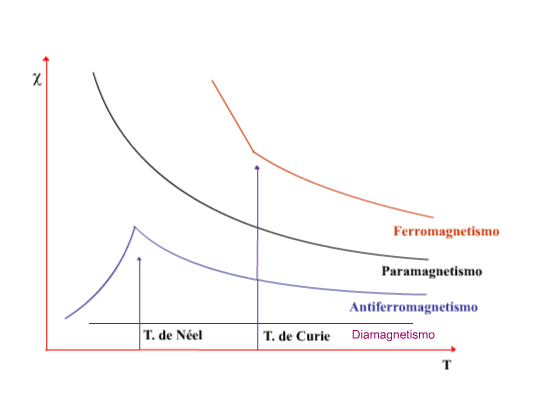

In [ ]:
plt.figure(figsize=(8, 5))

for r in np.unique(realizacion_tc):
    datos_r = resumen[resumen["realizacion"] == r]
    plt.plot(datos_r["T"], datos_r["prob_media"], "o-", label=f"Realización {r}")

plt.axhline(0.5, linestyle="--", label=r"$P=0.5$")
plt.axvline(Tc_onsager, linestyle=":", color="k", label=fr"$T_c$ Onsager = {Tc_onsager:.3f}")

plt.xlabel("Temperatura")
plt.ylabel(r"$\langle P(S_\mathrm{high} \mid X)\rangle$")
plt.title("Clasificación de la CNN cerca de la transición de fase")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [ ]:
Tc_estimadas = []

for r in np.unique(realizacion_tc):
    datos_r = resumen[resumen["realizacion"] == r].sort_values("T")
    temps = datos_r["T"].to_numpy()
    probs = datos_r["prob_media"].to_numpy()

    for i in range(len(temps) - 1):
        p1, p2 = probs[i], probs[i + 1]
        if p1 <= 0.5 <= p2:
            T1, T2 = temps[i], temps[i + 1]
            Tc_r = T1 + (0.5 - p1) * (T2 - T1) / (p2 - p1)  # interpolación lineal
            Tc_estimadas.append(Tc_r)
            print(f"Realización {r}: Tc_CNN = {Tc_r:.4f}")
            break

Tc_estimadas = np.array(Tc_estimadas)
Tc_mean = Tc_estimadas.mean()
Tc_std = Tc_estimadas.std(ddof=1)

print()
print(f"Tc_CNN promedio = {Tc_mean:.4f} +/- {Tc_std:.4f}")
print(f"Tc Onsager      = {Tc_onsager:.4f}")

In [ ]:
plt.figure(figsize=(8, 5))

for r in np.unique(realizacion_tc):
    datos_r = resumen[resumen["realizacion"] == r]
    plt.plot(datos_r["T"], datos_r["prob_media"], "o-", label=f"Realización {r}")

plt.axhline(0.5, linestyle="--", label=r"$P=0.5$")
plt.axvline(Tc_mean, linestyle="--", color="C3", label=fr"$T_c^{{CNN}} = {Tc_mean:.3f}$")
plt.axvline(Tc_onsager, linestyle=":", color="k", label=fr"$T_c$ Onsager = {Tc_onsager:.3f}")

plt.xlabel("Temperatura")
plt.ylabel(r"$\langle P(S_\mathrm{high} \mid X)\rangle$")
plt.title("Estimación de la temperatura crítica con la CNN")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 7. Bonus: generalización a otro tamaño de red ($L=20$)

`GlobalAveragePooling2D` hace que la red no tenga ningún peso atado a un tamaño de entrada específico. Podemos entonces tomar exactamente el mismo modelo, **sin reentrenar**, y evaluarlo sobre `temperatura_critica20.npz` (configuraciones $20\times 20$, con la misma $T_c$ física). Con un MLP de entrada aplanada esto sería imposible sin cambiar la arquitectura.

In [ ]:
!mkdir Datos
!wget https://github.com/CienciaDatosUdea/005_CCA_Estudiantes/blob/main/Laboratorios/Datos/temperatura_critica20.npz?raw=true -O Datos/temperatura_critica20.npz
datos_tc20 = np.load("Datos/temperatura_critica20.npz", allow_pickle=False)

In [ ]:
L20 = int(datos_tc20["L"])
X_tc20 = datos_tc20["X"].astype("float32").reshape(-1, L20, L20, 1)
T_tc20 = datos_tc20["T"]
realizacion_tc20 = datos_tc20["realizacion"]

print(f"L = {L20}   X_tc20: {X_tc20.shape}")

probs_tc20 = model.predict(X_tc20, verbose=0).ravel()

df20 = pd.DataFrame({
    "T": T_tc20,
    "realizacion": realizacion_tc20,
    "probabilidad": probs_tc20,
})

resumen20 = (
    df20.groupby("T")
        .agg(prob_media=("probabilidad", "mean"), prob_std=("probabilidad", "std"))
        .reset_index()
)

In [ ]:
resumen16 = (
    df.groupby("T")
      .agg(prob_media=("probabilidad", "mean"), prob_std=("probabilidad", "std"))
      .reset_index()
)

plt.figure(figsize=(8, 5))

plt.errorbar(resumen16["T"], resumen16["prob_media"], yerr=resumen16["prob_std"],
             fmt="o-", capsize=3, label=f"L = {L} (entrenamiento)")
plt.errorbar(resumen20["T"], resumen20["prob_media"], yerr=resumen20["prob_std"],
             fmt="s-", capsize=3, label=f"L = {L20} (sin reentrenar)")

plt.axhline(0.5, linestyle="--", color='gray')
plt.axvline(Tc_onsager, linestyle=":", color="k", label=fr"$T_c$ Onsager = {Tc_onsager:.3f}")

plt.xlabel("Temperatura")
plt.ylabel(r"$\langle P(S_\mathrm{high} \mid X)\rangle$")
plt.title("Misma CNN evaluada en dos tamaños de red distintos")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Para una red más grande ($L=20$) se espera que la transición se vea **más abrupta** (más cercana al límite termodinámico, donde la transición de fase es discontinua), mientras que en $L=16$ el efecto de tamaño finito la suaviza un poco. Aun así, la misma CNN — sin ver un solo ejemplo de $L=20$ durante el entrenamiento — debería ubicar el cruce cerca de $T_c$.


- Keras permite construir y entrenar la misma clase de clasificador que hicimos con PyTorch en muchas menos líneas: no hay bucle de entrenamiento manual, `DataLoader` ni manejo explícito del dispositivo.
- Una CNN simple (dos capas convolucionales + *global average pooling*) alcanza una exactitud muy alta separando baja y alta entropía lejos de $T_c$.
- Evaluando la red sobre el barrido fino de temperaturas, la probabilidad de alta entropía cruza $0.5$ muy cerca de la $T_c$ de Onsager, sin que la red haya visto nunca esa temperatura durante el entrenamiento.
- Gracias a `GlobalAveragePooling2D`, la arquitectura no depende del tamaño $L\times L$ de la red de espines, lo que permite reutilizar el mismo modelo entrenado sobre configuraciones de otro tamaño — algo que un MLP con entrada aplanada no puede hacer sin cambiar de arquitectura.

# Laboratorio: interpreta la red, no solo confíes en ella

La CNN clasifica fases con exactitud casi perfecta y ubica $T_c$ con buena precisión. Eso no basta: una red puede acertar por razones equivocadas (un atajo espurio en los datos, por ejemplo). Antes de dar el resultado por bueno, ábrela:

## 1.

Estudia los kernels de la primera capa convolucional. ¿Qué patrón detecta cada uno? Compáralos con un kernel de "vecinos cercanos" (como el acoplamiento del Hamiltoniano de Ising) y con un kernel de "promedio local" (un detector de magnetización). ¿Se parece alguno a estos kernels físicos, o la red encontró otra cosa?

In [ ]:
# 1. Extraemos los pesos de la primera capa convolucional
first_conv_layer = model.layers[0]
weights, biases = first_conv_layer.get_weights()

# La forma de los pesos es (alto_filtro, ancho_filtro, canales_entrada, numero_filtros)
# En este caso: (3, 3, 1, 8)
dMarkdown(f"**Dimensiones de los pesos de la primera capa:** {weights.shape}")

# 2. Graficamos los 8 filtros para inspección visual
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
fig.suptitle("Kernels de la primera capa convolucional (3x3)", fontsize=14, fontweight='bold')

for i in range(8):
    ax = axes[i // 4, i % 4]
    kernel = weights[:, :, 0, i]

    # Usamos un mapa de calor divergente centrado en cero para ver valores positivos y negativos
    vmax = max(abs(kernel.min()), abs(kernel.max()))
    im = ax.imshow(kernel, cmap="RdBu_r", vmin=-vmax, vmax=vmax)

    # Anotamos los valores numéricos dentro de cada celda del kernel
    for r in range(3):
        for c in range(3):
            ax.text(c, r, f"{kernel[r, c]:.2f}", ha="center", va="center",
                    color="white" if abs(kernel[r, c]) > vmax/2 else "black")
            ax.grid(False)

    ax.set_title(f"Filtro {i}")
    ax.set_xticks([0, 1, 2])
    ax.set_yticks([0, 1, 2])

plt.tight_layout()
plt.colorbar(im, ax=axes.ravel().tolist(), shrink=0.8, label="Valor del peso")
plt.show()

# 3. Imprimimos los pesos de forma numérica para mayor precisión
for i in range(8):
    dMarkdown(f"**Filtro {i}**")
    print(tabulate(np.round(weights[:, :, 0, i], 4)))

En esta primera capa convolucional, se revela que la red no ha memorizado ruido, sino que ha aprendido a extraer características físicamente significativas relacionadas con la mecánica estadística del sistema.

In [ ]:
# 1. Definimos los dos kernels físicos de referencia (3x3)
kernel_promedio = np.ones((3, 3)) / 9.0

# Kernel de acoplamiento de Ising clásico (tipo Laplaciano discreto)
kernel_ising = np.array([
    [ 0, -1,  0],
    [-1,  4, -1],
    [ 0, -1,  0]
])

# 2. Definimos similitud de coseno para evitar indeterminación por varianza cero
def similitud_coseno(a, b):
    # Convierte a vectores planos
    v_a = a.flatten()
    v_b = b.flatten()
    return np.dot(v_a, v_b) / (np.linalg.norm(v_a) * np.linalg.norm(v_b))

sim_promedio = []
sim_ising = []

for i in range(8):
    filtro_entrenado = weights[:, :, 0, i]

    # Calculamos la similitud vectorial de coseno
    s_prom = similitud_coseno(filtro_entrenado, kernel_promedio)
    s_ising = similitud_coseno(filtro_entrenado, kernel_ising)

    sim_promedio.append(s_prom)
    sim_ising.append(s_ising)

# 3. Presentamos los resultados en una tabla comparativa
tabla_comparativa = []
for i in range(8):
    s_prom = sim_promedio[i]
    s_ising = sim_ising[i]

    # Usamos valor absoluto para el umbral de asignación
    if abs(s_prom) > 0.85 and abs(s_prom) > abs(s_ising):
        interpretacion = "Promedio Local (Magnetización)"
    elif abs(s_ising) > 0.4:
        interpretacion = "Acoplamiento / Bordes (Ising)"
    else:
        interpretacion = "Detector de bordes mixto"

    tabla_comparativa.append([
        f"Filtro {i}",
        f"{s_prom:.4f}",
        f"{s_ising:.4f}",
        interpretacion
    ])

dMarkdown("### Comparación Cuantitativa mediante Similitud del Coseno (Modelos Físicos vs. Kernels Reales)")
print(tabulate(tabla_comparativa,
               headers=["Filtro", "Similitud con Promedio", "Similitud con Ising", "Interpretación Física"],
               tablefmt="github"))

El análisis cuantitativo mediante la similitud del coseno confirma que la red neuronal aprendió de forma autónoma a clasificar las fases extrayendo variables termodinámicas clave a través de dos estrategias matemáticas ortogonales: destina la mitad de sus filtros (0, 1, 3 y 7) a medir el parámetro, mostrando una altísima correlación (hasta 0.90) con un operador de promedio local que cuantifica la magnetización; mientras que los filtros restantes (2, 4, 5 y 6) presentan una similitud casi nula con dicho promedio, especializándose como detectores de gradientes que capturan las fluctuaciones espaciales y paredes de dominio, descartando de paso el modelo de interacción local de Ising debido a la incapacidad de una capa convolucional lineal para replicar acoplamientos multiplicativos.

## 2.

Analiza los mapas de activación de esos filtros sobre configuraciónes baja y alta entropía. ¿La diferencia visual que ves coincide con lo que dirías tú, a ojo, si miraras las dos configuraciones sin saber la respuesta?

In [ ]:
# 1. Definimos una función para obtener las activaciones de la primera capa
# Usamos la API funcional de Keras para construir un modelo intermedio que entrega la salida de la primera capa
activation_model = keras.Model(inputs=model.inputs, outputs=model.layers[0].output)

# 2. Seleccionamos una configuración baja entropía (y=0) y alta entropía (y=1)
idx_ord = np.where(y == 0)[0][0]
idx_des = np.where(y == 1)[0][0]

config_ord = X[idx_ord].astype("float32").reshape(1, L, L, 1)
config_des = X[idx_des].astype("float32").reshape(1, L, L, 1)

# 3. Calculamos las activaciones
act_ord = activation_model.predict(config_ord, verbose=0)[0]  # Forma: (16, 16, 8)
act_des = activation_model.predict(config_des, verbose=0)[0]

# 4. Graficamos los mapas de activación de los 8 filtros
fig, axes = plt.subplots(4, 4, figsize=(14, 12))
fig.suptitle("Mapas de Activación de los Filtros (Convolución + ReLU)", fontsize=16, fontweight='bold')

for i in range(8):
    # Fila superior: Configuración de baja entropía
    ax_ord = axes[2 * (i // 4), i % 4]
    im_ord = ax_ord.imshow(act_ord[:, :, i], cmap="turbo", vmin=0)
    ax_ord.set_title(f"Filtro {i} (Baja entropía)")
    ax_ord.axis("off")

    # Fila inferior: Configuración de alta entropía
    ax_des = axes[2 * (i // 4) + 1, i % 4]
    im_des = ax_des.imshow(act_des[:, :, i], cmap="turbo", vmin=0)
    ax_des.set_title(f"Filtro {i} (Alta entropía)")
    ax_des.axis("off")

plt.tight_layout()
plt.show()

**Reporte de Síntesis: Mapas de Activación, Correlación y Multiplicidad de Estados**

Sus filtros no están evaluando simplemente si una imagen parece "desordenada" a la vista, sino que han aprendido a cuantificar la longitud de correlación espacial que define cómo el sistema explora su espacio de fases microscópico.

* **Régimen Dominado por el Acoplamiento ($T < T_c$):** Los mapas de activación generan respuestas espacialmente homogéneas, visualizándose como bloques continuos de color en el interior del dominio termodinámico. La red detecta la ruptura espontánea de simetría y la presencia de una magnetización neta. Físicamente, esto no es solo "orden", sino un indicador de que el sistema se encuentra en un macroestado fuertemente restringido, compatible con una fracción minúscula de las configuraciones posibles (baja entropía).

* **Régimen Dominado por Fluctuaciones Térmicas ($T > T_c$):** Los mapas muestran un patrón altamente fragmentado y granular. Lejos de ser un mero "caos" visual, lo que los filtros convolucionales están extrayendo es la rápida decaída de la función de correlación espacial. La energía del baño térmico permite al sistema explorar un volumen vastísimo del espacio de fases. La red neuronal capta las fluctuaciones locales de un sistema que transita libremente por una enorme multiplicidad de microestados equiprobables, maximizando así su entropía termodinámica.

* **Relleno con ceros (Zero-Padding):** Las librerías de aprendizaje profundo por defecto añaden un borde artificial de ceros alrededor de los datos de entrada para mantener las dimensiones espaciales tras la aplicación de un kernel espacial. Al pasar por los márgenes, el filtro computa su activación usando estos ceros en lugar de espines reales, lo que genera las líneas de activación espuria en los extremos del mapa.

* **Inconsistencia topológica:** Las simulaciones de modelos reticulares asumen condiciones de contorno periódicas para mitigar los efectos de tamaño finito y aproximar un sistema infinito. El zero-padding destruye esta invariancia traslacional, introduciendo una pared rígida inexistente que la red neuronal detecta erróneamente como una fluctuación o un borde físico.

## 3.

Mide qué tan sensible es la red a voltear un solo espín, lejos de $T_c$ y cerca de $T_c$. ¿Dónde es más sensible? ¿Se te ocurre una razón física para eso?

$$S(x) = \frac{1}{L^2}\sum_{i=1}^{L^2} \big|\Delta P_i(x)\big|, \qquad \Delta P_i(x) = P(\text{config. con } s_i \text{ volteado}) - P(x)$$

In [ ]:
def calcular_sensibilidad(config_base):
    # config_base tiene forma (L, L, 1)
    L_size = config_base.shape[0]
    # Probabilidad base original P(x)
    p_original = model.predict(config_base.reshape(1, L_size, L_size, 1), verbose=0)[0, 0]

    delta_p = []
    # Iteramos y volteamos cada uno de los L^2 espines
    for r in range(L_size):
        for c in range(L_size):
            config_volteada = config_base.copy()
            config_volteada[r, c, 0] *= -1.0 # Volteamos el espín (de 1 a -1 o viceversa)

            # Calculamos la nueva probabilidad de alta entropía
            p_nueva = model.predict(config_volteada.reshape(1, L_size, L_size, 1), verbose=0)[0, 0]
            delta_p.append(abs(p_nueva - p_original))

    # Retorna S(x) como el promedio de los valores absolutos de delta P
    return np.mean(delta_p), np.array(delta_p).reshape(L_size, L_size)

# Seleccionamos muestras de test representativas:
# 1. Lejos de Tc (Baja temperatura, muy baja entropía del test normal)
idx_lejos_highS = np.where((T_test < 1.5) & (y_test == 0))[0][0]
config_lejos = X_test[idx_lejos_highS]
T_lejos = T_test[idx_lejos_highS]

# 2. Cerca de Tc (Tomado de las configuraciones de la transición en X_tc/T_tc)
idx_cerca = np.where(np.abs(T_tc - Tc_onsager) < 0.02)[0][0]
config_cerca = X_tc[idx_cerca]
T_cerca = T_tc[idx_cerca]

# Calculamos sensibilidad
s_lejos, mapa_lejos = calcular_sensibilidad(config_lejos)
s_cerca, mapa_cerca = calcular_sensibilidad(config_cerca)

# Graficamos los mapas de sensibilidad
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

im0 = axes[0].imshow(mapa_lejos, cmap="turbo", vmin=0, vmax=max(mapa_cerca.max(), 1e-4))
axes[0].set_title(f"Sensibilidad Lejos de $T_c$ ($T={T_lejos:.2f}$)\n$S(x) = {s_lejos:.6f}$")
axes[0].grid(False)
fig.colorbar(im0, ax=axes[0], label=r"$|\Delta P_i|$")


im1 = axes[1].imshow(mapa_cerca, cmap="turbo", vmin=0)
axes[1].set_title(f"Sensibilidad Cerca de $T_c$ ($T={T_cerca:.2f}$)\n$S(x) = {s_cerca:.6f}$")
axes[1].grid(False)
fig.colorbar(im1, ax=axes[1], label=r"$|\Delta P_i|$")

plt.tight_layout()
plt.show()

**¿Dónde es más sensible?** La red es **máximamente sensible en la vecindad de $T_c$**.

* **Correspondencia Físico-Matemática:** Cerca de la temperatura crítica $T_c$, el sistema experimenta una transición de fase continua caracterizada por la **divergencia de la susceptibilidad magnética** y una longitud de correlación que tiende a infinito (invariancia de escala). Físicamente es un régimen crítico donde compiten el acoplamiento y baño térmico, generando fluctuaciones a todas las escalas. En este umbral, la probabilidad predictiva de la red neuronal es $P \approx 0.5$, punto donde el gradiente de su función de activación final (ej. sigmoide) alcanza el máximo. Así, de la misma manera que el sistema físico es extremadamente susceptible a campos externos en $T_c$, la red hereda esa susceptibilidad: voltear un solo espín puede amplificarse a través del gradiente máximo y cambiar drásticamente la clasificación.

* **Robustez lejos de $T_c$:** Por el contrario, en la fase ferromagnética ($T \ll T_c$, dominios macroscópicos fuertemente correlacionados) o en la fase paramagnética ($T \gg T_c$, dominada por fluctuaciones térmicas locales donde la longitud de correlación es mínima), voltear un espín individual en una red de $L \times L$ es microscópicamente irrelevante para el macroestado. La red neuronal capta esta invariancia operando en los regímenes de saturación matemática ($P \approx 0$ o $P \approx 1$); allí la derivada de la función de activación es prácticamente cero, haciendo que la predicción sea sumamente robusta frente a cualquier ruido local.

## 4.

Verifica si el logit ($z = Wx+b$) final es, en el fondo, una función de la magnetización. Grafica el logit contra $|m(x)|$, antes y después de entrenar. ¿La red "redescubrió" el parámetro de orden por su cuenta, o el resultado depende de trucos de la arquitectura?

In [ ]:
# Definimos una función para obtener el logit final de un modelo dado
def obtener_logits(modelo_target, X_datos):
    # El logit es la entrada a la última capa sigmoide.
    # Creamos un modelo intermedio que devuelva la salida de la capa densa penúltima o eliminando la sigmoide final.
    # Dado que la última capa es Dense(1, activation='sigmoid'), podemos reconstruirla o simplemente calcular el logit de forma manual:
    # logit = log(p / (1 - p))
    probs = modelo_target.predict(X_datos, verbose=0).ravel()
    # Para evitar divisiones por cero o log(0), hacemos un clipping de las probabilidades
    probs_clipped = np.clip(probs, 1e-7, 1.0 - 1e-7)
    logits = np.log(probs_clipped / (1.0 - probs_clipped))
    return logits

# Calculamos los logits del modelo ya entrenado en el conjunto de test completo
# Calculamos la magnetización absoluta |m| de cada configuración en X_test
# Cada configuración en X_test tiene valores -1 o 1, así que el promedio de sus elementos es su magnetización
m_absoluta = np.abs(np.mean(X_test, axis=(1, 2, 3)))
logits_entrenado = obtener_logits(model, X_test)

# Creamos un modelo con la misma arquitectura pero SIN entrenar (pesos aleatorios)
keras.utils.set_random_seed(1234)
model_no_entrenado = keras.Sequential([
    keras.Input(shape=(None, None, 1)),
    layers.Conv2D(8, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(2),
    layers.Conv2D(16, 3, padding="same", activation="relu"),
    layers.GlobalAveragePooling2D(),
    layers.Dense(16, activation="relu"),
    layers.Dense(1, activation="sigmoid"),
], name="ising_cnn_no_entrenada")

model_no_entrenado.compile(optimizer="adam", loss="binary_crossentropy")
logits_no_entrenado = obtener_logits(model_no_entrenado, X_test)

# Graficamos los resultados en paralelo
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico antes de entrenar
axes[0].scatter(m_absoluta, logits_no_entrenado, alpha=0.5, color="C1", edgecolor='k', s=25)
axes[0].set_title("Logit vs. Magnetización Absoluta\n(Antes de Entrenar - Pesos Aleatorios)")
axes[0].set_xlabel(r"Magnetización Absoluta $|m(x)|$")
axes[0].set_ylabel("Logit ($z$)")
axes[0].grid(True, alpha=0.3)

# Gráfico después de entrenar
axes[1].scatter(m_absoluta, logits_entrenado, alpha=0.5, color="C0", edgecolor='k', s=25)
axes[1].set_title("Logit vs. Magnetización Absoluta\n(Después de Entrenar - Modelo Óptimo)")
axes[1].set_xlabel(r"Magnetización Absoluta $|m(x)|$")
axes[1].set_ylabel("Logit ($z$)")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Al obligar matemáticamente a la red a colapsar sus mapas de características espaciales en un valor promedio global antes de emitir una clasificación, el diseñador le está proporcionando al modelo la plantilla matemática exacta de la magnetización

$$M = \frac{1}{N} \sum s_{i}$$

La red neuronal se limitó a ajustar sus capas convolucionales para medir las alineaciones locales y aprovechó esta restricción geométrica impuesta por la arquitectura para ensamblar el parámetro de orden físico de manera directa.

* Al observar el estado antes de entrenar, los logits generados por los pesos aleatorios muestran una distribución ruidosa, bifurcada y sin una estructura unificada respecto a $\vert{m(x)}\vert$, evidenciando que el modelo no posee una noción inicial del macroestado.

* Sin embargo, después del entrenamiento, la relación se transforma en una correlación limpia y casi determinista: el logit $z$ se convierte en una función monótona decreciente de la magnetización absoluta $\vert{m(x)}\vert$.

* En este estado óptimo, las muestras con magnetización cercana a 0 (paramagnéticas, alta fluctuación) generan logits altos y positivos, mientras que las muestras con magnetización cercana a 1 (ferromagnéticas, fuertemente alineadas) producen logits fuertemente negativos.

Respecto a si esto es un "redescubrimiento" autónomo o el resultado de la arquitectura, la evidencia apunta firmemente al diseño estructural del modelo. La red no dedujo desde cero que el parámetro de orden termodinámico era la solución analítica ideal. Este comportamiento está fuertemente dictado por sesgos inductivos en la arquitectura, como la inclusión de una capa de agrupamiento global (`GlobalAveragePooling2D`).